# <center>**Figure 04 : Neuron Cluster Statistics**</center>

In [1]:
# General
import os
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, linregress
from prats_helpers import place_panel_label

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("ticks")

In [2]:
projects_home = os.environ["PROJECTS_HOME"]
neu_info_path = f"{projects_home}/L1_Skeletons/Data_Summary/L1_NeuronInformation_PK.csv"
folder        = "../Figures"

## Load and Filter Data

In [3]:
neu_df = pd.read_csv(neu_info_path)
df     = neu_df.loc[~(neu_df["Cluster"].isna())].copy()

df["bodyId"] = df["bodyId"].astype(int)
df.fillna("NA", inplace = True)

df = df.loc[~(df["Lineage"].str.contains("S-"))     &
            ~(df["Lineage"].str.contains("Unbound")) &
            ~(df["Lineage"].str.contains("Bolwig"))]
df["Count"] = 1

df.head(10)

,bodyId,Lineage,Category,Cluster,Instance,Acronym,Hemisphere,Moniker,Identifier,ConnectivityGroup,VolkerClass,Count
0,3690921,BAla1/2,Diff,1,b,Tdl|Mac,Right,NA,TRdl.s-|-MB-CA.s-MB-ACA.s.b,g135,BAla1/2_Tdl|Mac,1
1,3002410,BAla1/2,Diff,1,a,Tdl|Mac,Right,NA,TRdl.s-|-MB-ACA.s.b,g135,BAla1/2_Tdl|Mac,1
2,4108016,BAla1/2,Diff,1,a,Tdl|Mac,Left,NA,TRdl.s-TRdm.s-|-MB-ACA.s.b,g135,BAla1/2_Tdl|Mac,1
3,4154421,BAla1/2,Diff,1,b,Tdl|Mac,Left,NA,TRdl.s-|-MB-ACA.s.b,g135,BAla1/2_Tdl|Mac,1
4,17107661,BAla1/2,Diff,2,NA,Tdl|ICmed,Right,NA,TRdl.s-VMCpv.s-|-IPLM.s.b-SLPl.s.b,g121,BAla1/2_Tdl|ICmed,1
5,8838927,BAla1/2,Diff,2,NA,Tdl|ICmed,Left,NA,VMCpv.s-TRdl.s-MXneu.s-VMCpd.s-|-SLPl.s-IPLM.s...,g121,BAla1/2_Tdl|ICmed,1
6,13242336,BAla1/2,Diff,3,b,Tdl|ICmed,Right,NA,TRdl.s-VMCpv.s-|-IPLM.s.b-VMCpd.s.b,g121,BAla1/2_Tdl|ICmed,1
7,13167730,BAla1/2,Diff,3,a,Tdl|ICmed,Right,NA,TRdl.s-VMCpv.s-|-VMCpd.s.b-IPLM.b,g121,BAla1/2_Tdl|ICmed,1
8,19166349,BAla1/2,Diff,3,a,Tdl|ICmed,Left,NA,TRdl.s-VMCpv.s-|-VMCpd.s.b-IPLM.s.b,g121,BAla1/2_Tdl|ICmed,1
9,12500843,BAla1/2,Diff,3,b,Tdl|ICmed,Left,NA,TRdl.s-|-VMCpd.s.b-IPLM.s.b,g121,BAla1/2_Tdl|ICmed,1


## Cluster Size Statistics

In [4]:
# Mean cluster size per lineage, averaged across hemispheres
size_df = (df.groupby(["Lineage", "Hemisphere", "Category", "Cluster"])["Count"]
             .sum()
             .reset_index())
size_df = size_df.loc[size_df["Category"].isin(["Diff", "SU"])]

mean_size_df = (size_df.groupby(["Lineage", "Category", "Cluster"])["Count"]
                       .mean()
                       .reset_index())

diff_neu_mean = mean_size_df.loc[mean_size_df["Category"] == "Diff", "Count"].mean()
su_neu_mean   = mean_size_df.loc[mean_size_df["Category"] == "SU",   "Count"].mean()

## Acronym (VolkerClass) Statistics

In [5]:
# Mean neurons per VolkerClass, averaged over Hemisphere x Cluster
_acr_hemi        = (df.groupby(["VolkerClass", "Hemisphere", "Cluster"])["Count"]
                      .sum()
                      .reset_index())
acronym_count_df = (_acr_hemi.groupby(["VolkerClass"])["Count"]
                              .mean()
                              .reset_index())
acronym_count_df = acronym_count_df.loc[acronym_count_df["VolkerClass"] != "NA"]

#------------------------------------------------------------------------------
# Unique cluster types per VolkerClass
_acr_clusters          = (df.groupby(["VolkerClass", "Cluster"])["Count"]
                             .sum()
                             .reset_index())
_acr_clusters          = _acr_clusters.loc[~(_acr_clusters["VolkerClass"].str.contains("NA"))]
_acr_clusters["Count"] = 1
acronym_df             = _acr_clusters.groupby(["VolkerClass"])["Count"].sum().reset_index()

cl_per_acr  = np.mean(acronym_df["Count"])
neu_per_acr = np.mean(acronym_count_df["Count"])

## Intra-Lineage Cell Type Diversity

In [6]:
lineages = np.unique(df["Lineage"])

#------------------------------------------------------------------------------
counts = []
for lin in lineages:
    lin_df   = df.loc[df["Lineage"] == lin]
    num_diff = len(np.unique(lin_df.loc[lin_df["Category"] == "Diff", "Cluster"]))
    num_acr  = len(np.unique(lin_df.loc[lin_df["Category"] == "Diff", "Acronym"]))
    num_su   = len(np.unique(lin_df.loc[lin_df["Category"] == "SU",   "Cluster"]))

    counts.append({"Lineage" : lin, "Category" : "Diff", "Level" : "Type",  "Count" : int(num_diff)})
    counts.append({"Lineage" : lin, "Category" : "Diff", "Level" : "Class", "Count" : int(num_acr)})
    counts.append({"Lineage" : lin, "Category" : "SU",   "Level" : "Type",  "Count" : int(num_su)})

cluster_df              = pd.DataFrame(counts)
cluster_df["Hierarchy"] = cluster_df["Category"] + "-" + cluster_df["Level"]

cluster_df.to_csv("../Analysis_Outputs/L1_Lineage-Cluster-Acronym_Counts.csv", index = False)

#------------------------------------------------------------------------------
diff_pivot = (
    cluster_df[cluster_df["Category"] == "Diff"]
    .pivot(index = "Lineage", columns = "Level", values = "Count")
    .reset_index()
    .rename(columns = {"Type" : "Diff_Type_Count", "Class" : "Diff_Class_Count"})
    .fillna(0)
)

diff_type_mean  = np.mean(cluster_df.loc[cluster_df["Hierarchy"] == "Diff-Type",  "Count"])
diff_class_mean = np.mean(cluster_df.loc[cluster_df["Hierarchy"] == "Diff-Class", "Count"])
su_type_mean    = np.mean(cluster_df.loc[cluster_df["Hierarchy"] == "SU-Type",    "Count"])

cluster_df.head(10)

,Lineage,Category,Level,Count,Hierarchy
0,BAla1/2,Diff,Type,18,Diff-Type
1,BAla1/2,Diff,Class,11,Diff-Class
2,BAla1/2,SU,Type,1,SU-Type
3,BAla3/4,Diff,Type,19,Diff-Type
4,BAla3/4,Diff,Class,19,Diff-Class
5,BAla3/4,SU,Type,4,SU-Type
6,BAlc,Diff,Type,17,Diff-Type
7,BAlc,Diff,Class,11,Diff-Class
8,BAlc,SU,Type,4,SU-Type
9,BAlp1-3,Diff,Type,11,Diff-Type


## Style Parameters

In [7]:
linewidth      = 0.75
scatter_size   = 6
scatter_alpha  = 0.75
linewidth_hist = 0.5
alpha_hist     = 0.35
title_fontsize = 8.5
label_fontsize = 7
tick_fontsize  = 6

# Labels
label_kwargs = dict(fontsize = 16, va = "center", ha = "left")
shy  = 0.0

# Palettes
palette  = {"Diff-Type" : "#4C72B0", "Diff-Class" : "#DD8452", "SU-Type" : "#55A868"}
palette2 = {"Type"      : "#4C72B0", "Class"      : "#DD8452"}
palette3 = {"Diff"      : "#4C72B0", "SU"         : "#55A868"}

## Main Figure

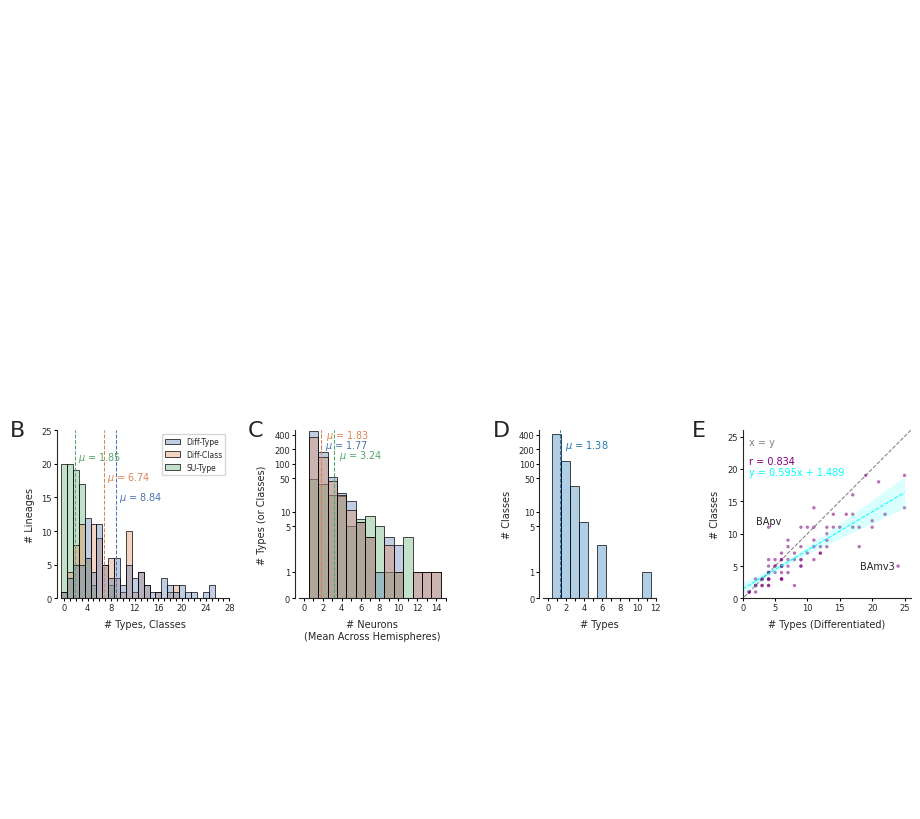

In [8]:
labelpad   = 5
offset     = 0.5
xp         = 0.98
fill_alpha = 0.2

#------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize = (8.5, 8),
                       ncols = 4, nrows = 4,
                       sharey = False, sharex = False)
plt.subplots_adjust(hspace = 0.25, wspace = 0.35,
                    top = 1, bottom = 0, right = 1, left = 0)

# Turn off unused rows and columns
for a in ax[:2, :].flatten():
    a.axis("off")
for a in ax[3, :].flatten():
    a.axis("off")


# Tick params for the histogram/scatter row
for a in ax[2, :]:
    a.tick_params(
        axis      = "both",
        which     = "major",
        color     = "black",
        labelsize = tick_fontsize,
        length    = 2,
        width     = 0.75,
        pad       = 1.5)
    sns.despine(ax = a)

# Create offsets in first three panels
for a in ax[2, :-1]:
    sns.despine(ax = a, offset = {"left" : 3})

#------------------------------------------------------------------------------
# Panel B - Histogram: Types, Classes, and SU Types per Lineage
sns.histplot(
    data      = cluster_df,
    x         = "Count",
    alpha     = alpha_hist,
    hue       = "Hierarchy",
    ax        = ax[2, 0],
    linewidth = linewidth_hist,
    palette   = palette,
    edgecolor = "black",
    binwidth  = 1,
    binrange  = (0, 30))

ax[2, 0].set_xlim(0, 27)
ax[2, 0].set_ylim(0, 25)

ax[2, 0].set_xticks(np.linspace(0, 28, 29) + offset)
all_labels     = np.linspace(0, 28, 29).astype(int)
display_labels = [str(int(lab)) if i % 4 == 0 else "" for i, lab in enumerate(all_labels)]
ax[2, 0].set_xticklabels(display_labels)

ax[2, 0].set_xlabel("# Types, Classes", fontsize = label_fontsize, labelpad = labelpad)
ax[2, 0].set_ylabel("# Lineages",       fontsize = label_fontsize, labelpad = labelpad)

sns.move_legend(ax[2, 0], loc = "upper right", bbox_to_anchor = (1, 1),
                fontsize = label_fontsize - 1.5,
                title = "")

ax[2, 0].axvline(diff_type_mean + offset,  color = palette["Diff-Type"],  linewidth = linewidth, linestyle = "--")
ax[2, 0].axvline(diff_class_mean + offset, color = palette["Diff-Class"], linewidth = linewidth, linestyle = "--")
ax[2, 0].axvline(su_type_mean + offset,    color = palette["SU-Type"],    linewidth = linewidth, linestyle = "--")

ax[2, 0].text(diff_type_mean + (offset * 2), 15, f"$\\mu$ = {diff_type_mean:.2f}",
              fontsize = label_fontsize, color = palette["Diff-Type"],  va = "center")
ax[2, 0].text(diff_class_mean + (offset * 2), 18, f"$\\mu$ = {diff_class_mean:.2f}",
              fontsize = label_fontsize, color = palette["Diff-Class"], va = "center")
ax[2, 0].text(su_type_mean + (offset * 2), 21, f"$\\mu$ = {su_type_mean:.2f}",
              fontsize = label_fontsize, color = palette["SU-Type"],    va = "center")

#------------------------------------------------------------------------------
# Panel C - Histogram: Neurons per Type or Class
sns.histplot(
    data      = mean_size_df,
    x         = "Count",
    alpha     = alpha_hist,
    hue       = "Category",
    palette   = palette3,
    ax        = ax[2, 1],
    linewidth = linewidth_hist,
    edgecolor = "black",
    binwidth  = 1,
    binrange  = (0, 25))

sns.histplot(
    data      = acronym_count_df,
    x         = "Count",
    alpha     = alpha_hist,
    color     = palette["Diff-Class"],
    label     = "Class",
    ax        = ax[2, 1],
    linewidth = linewidth_hist,
    edgecolor = "black",
    binwidth  = 1,
    binrange  = (0, 25))

ax[2, 1].legend().set_visible(False)
ax[2, 1].set_xlim(0, 15)
ax[2, 1].set_ylim(0, 500)
ax[2, 1].set_yscale("symlog")
ax[2, 1].set_yticks([0, 1, 5, 10, 50, 100, 200, 400])
ax[2, 1].set_yticklabels([0, 1, 5, 10, 50, 100, 200, 400])
ax[2, 1].set_box_aspect(1.15)

# X Labels
all_labels     = np.linspace(0, 15, 16).astype(int)
display_labels = [str(int(lab)) if i % 2 == 0 else "" for i, lab in enumerate(all_labels)]
ax[2, 1].set_xticks(all_labels + offset, labels = display_labels)

ax[2, 1].set_xlabel("# Neurons\n(Mean Across Hemispheres)", fontsize = label_fontsize, labelpad = labelpad)
ax[2, 1].set_ylabel("# Types (or Classes)",                fontsize = label_fontsize, labelpad = labelpad)

ax[2, 1].axvline(diff_neu_mean + offset, color = palette3["Diff"],      linewidth = linewidth, linestyle = "--")
ax[2, 1].axvline(su_neu_mean + offset,   color = palette3["SU"],        linewidth = linewidth, linestyle = "--")
ax[2, 1].axvline(neu_per_acr + offset,   color = palette["Diff-Class"], linewidth = linewidth, linestyle = "--")

ax[2, 1].text(diff_neu_mean + (offset * 2), 250, f"$\\mu$ = {diff_neu_mean:.2f}",
              fontsize = label_fontsize, color = palette3["Diff"],      va = "center")
ax[2, 1].text(neu_per_acr + (offset * 2),   400, f"$\\mu$ = {neu_per_acr:.2f}",
              fontsize = label_fontsize, color = palette["Diff-Class"], va = "center")
ax[2, 1].text(su_neu_mean + (offset * 2),   150, f"$\\mu$ = {su_neu_mean:.2f}",
              fontsize = label_fontsize, color = palette3["SU"],        va = "center")

#------------------------------------------------------------------------------
# Panel D - Histogram: Types per VolkerClass
acr_color = "#1f77b4"
sns.histplot(
    data      = acronym_df,
    x         = "Count",
    alpha     = alpha_hist,
    color     = acr_color,
    ax        = ax[2, 2],
    linewidth = linewidth_hist,
    edgecolor = "black",
    binwidth  = 1,
    binrange  = (0, 13))

ax[2, 2].set_xlim(0, 12)
ax[2, 2].set_ylim(0, 500)
ax[2, 2].set_yscale("symlog")
ax[2, 2].set_yticks([0, 1, 5, 10, 50, 100, 200, 400])
ax[2, 2].set_yticklabels([0, 1, 5, 10, 50, 100, 200, 400])
ax[2, 2].set_box_aspect(1.5)

# ax[2, 2].set_xticks(np.linspace(0, 12, 13) + offset, labels = np.linspace(0, 12, 13).astype(int))

# X Labels
all_labels     = np.linspace(0, 12, 13).astype(int)
display_labels = [str(int(lab)) if i % 2 == 0 else "" for i, lab in enumerate(all_labels)]
ax[2, 2].set_xticks(all_labels + offset, labels = display_labels)

ax[2, 2].set_xlabel("# Types",   fontsize = label_fontsize, labelpad = labelpad)
ax[2, 2].set_ylabel("# Classes", fontsize = label_fontsize, labelpad = labelpad)

ax[2, 2].axvline(cl_per_acr + offset, linewidth = linewidth, linestyle = "--", color = acr_color)
ax[2, 2].text(cl_per_acr + offset * 2, 250, f"$\\mu$ = {cl_per_acr:.2f}",
              fontsize = label_fontsize, color = acr_color, va = "center")

#------------------------------------------------------------------------------
# Panel E - Scatter: Types vs Classes per Lineage
r, _                 = pearsonr(diff_pivot["Diff_Type_Count"], diff_pivot["Diff_Class_Count"])
slope, intercept, *_ = linregress(diff_pivot["Diff_Type_Count"], diff_pivot["Diff_Class_Count"])

sns.regplot(
    data = diff_pivot,
    x    = "Diff_Type_Count",
    y    = "Diff_Class_Count",
    ax   = ax[2, 3],
    scatter_kws = {"alpha"     : scatter_alpha * 0.75,
                   "color"     : "purple",
                   "s"         : scatter_size,
                   "edgecolor" : "none"},
    line_kws    = {"color"     : "cyan",
                   "linewidth" : linewidth,
                   "linestyle" : "--"})

ax[2, 3].set_xlabel("# Types (Differentiated)", fontsize = label_fontsize, labelpad = labelpad)
ax[2, 3].set_ylabel("# Classes",                fontsize = label_fontsize, labelpad = labelpad)
ax[2, 3].set_xlim(0, 26)
ax[2, 3].set_ylim(0, 26)

ax[2, 3].plot([-10, 50], [-10, 50], color = "grey", zorder = 0, linewidth = linewidth, linestyle = "--")

ax[2, 3].text(1, 25, "x = y",
              color = "grey", verticalalignment = "top", horizontalalignment = "left",
              fontsize = label_fontsize)
ax[2, 3].text(1, 22, f"r = {r:.3f}",
              verticalalignment = "top", horizontalalignment = "left",
              fontsize = label_fontsize, color = "purple")
ax[2, 3].text(1, 20.35, f"y = {slope:.3f}x + {intercept:.3f}",
              verticalalignment = "top", horizontalalignment = "left",
              fontsize = label_fontsize, color = "cyan")

ax[2, 3].text(23.5, 5,  "BAmv3",
              verticalalignment = "center", horizontalalignment = "right",
              fontsize = label_fontsize)
ax[2, 3].text(4, 12, "BApv",
              verticalalignment = "center", horizontalalignment = "center",
              fontsize = label_fontsize)

# Place Panel Labels
place_panel_label(fig, ax[2, 0], "B", shx = -0.06,  shy = shy, label_kwargs = label_kwargs)
place_panel_label(fig, ax[2, 1], "C", shx = -0.06, shy = shy, label_kwargs = label_kwargs)
place_panel_label(fig, ax[2, 2], "D", shx = -0.06, shy = shy, label_kwargs = label_kwargs)
place_panel_label(fig, ax[2, 3], "E", shx = -0.06, shy = shy, label_kwargs = label_kwargs)

#------------------------------------------------------------------------------
plt.savefig(f"{folder}/Figure_04_Panels-Cluster-Acronym-Stats.pdf", dpi = 1200, bbox_inches = "tight")

## Supplementary Figure 01

In [9]:
prats_order = [
    "BAla1/2",  "BAla3/4",  "BAlc",     "BAlp1-3",  "BAlp4",    "BAlv",
    "BAmas1/2", "BAmd1",    "BAmd2",    "BAmv1/2",  "BAmv3",    "BApd",    "BApv",
    "BLAd1-4",  "BLAl",     "BLAv1/2",  "BLAvm",    "BLD1",     "BLD2-4",  "BLD5/6",
    "BLP1/2",   "BLP3/4",   "BLVa1/2",  "BLVa3/4",  "BLVp1",   "BLVp2",
    "CP1d",     "CP1v",     "CP4",
    "DALcl1/2d", "DALcl1/2v", "DALcm1/2m", "DALcm1/2v",
    "DALd",     "DALl1",
    "DALv1",    "DALv2/3",  "DALv2/3accl", "DALv2/3accm", "DALv2/3accvm", "DALv2/3accvl",
    "DAMd1",    "DAMd2/3",  "DAMv1/2",
    "DILP",
    "DPLal1-3", "DPLam",    "DPLc1",    "DPLc2",    "DPLc3",    "DPLc4",
    "DPLc5a",   "DPLc5p",   "DPLd",     "DPLl1-3",  "DPLm1",    "DPLm2",   "DPLp1/2",
    "DPMl1",    "DPMl2",    "DPMl3/4a", "DPMl3/4p", "DPMm2",
    "DPMpl1/2", "DPMpl3",
    "MB-AL",    "MB-AM",    "MB-PL",    "MB-PM",
    "OLP",
    "TRdc",     "TRdm",     "TRdl-a/b", "TRdl-c",   "TRdl-d",   "TRdl-e",  "TRvm",   "TRmotor",
    "",
    "CP2/3d",   "CP2/3v",   "DPMm1",    "DPMpm1",   "DPMpm2",   "CM4",     "CM4-CM5*", "CM1/3"
]

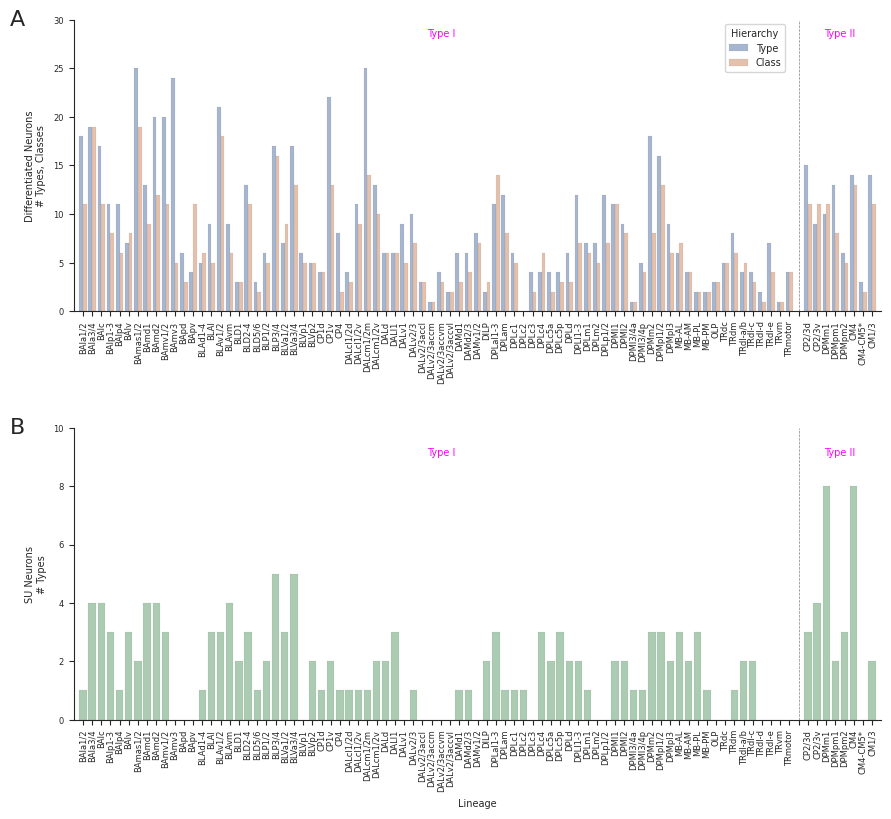

In [10]:
width  = 8.5
height = 7
fig, ax = plt.subplots(figsize = (width, height), nrows = 2, ncols = 1,
                       sharex = False)
plt.subplots_adjust(hspace = 0.4, top = 1, bottom = 0,
                    left = 0, right = 0.95)

#------------------------------------------------------------------------------
# Panel A - Differentiated Neurons: Types and Classes per Lineage
sns.barplot(
    cluster_df.loc[cluster_df["Category"] == "Diff"],
    x         = "Lineage",
    y         = "Count",
    hue       = "Level",
    ax        = ax[0],
    alpha     = alpha_hist * 1.5,
    palette   = palette2,
    edgecolor = "black",
    linewidth = 0.05,
    order     = prats_order)

#------------------------------------------------------------------------------
# Panel B - SU Neurons: Types per Lineage
sns.barplot(
    cluster_df.loc[cluster_df["Category"] == "SU"],
    x         = "Lineage",
    y         = "Count",
    ax        = ax[1],
    alpha     = alpha_hist * 1.5,
    color     = "#55A868",
    edgecolor = "black",
    linewidth = 0.05,
    order     = prats_order)

#------------------------------------------------------------------------------
ax[0].set_ylabel("Differentiated Neurons\n# Types, Classes", fontsize = label_fontsize, labelpad = 5)
ax[1].set_ylabel("SU Neurons\n# Types",                      fontsize = label_fontsize, labelpad = 5)

for a in ax:
    a.tick_params(axis = "x", which = "major", labelsize = tick_fontsize, rotation = 90)
    a.tick_params(axis = "y", which = "major", labelsize = tick_fontsize)
    a.set_xlim(-1, 87)
    a.set_ylim(0, 30)
    a.set_xlabel("")
    sns.despine(ax = a)
    a.axvline(x = 78, color = "grey", linestyle = "--", linewidth = 0.5)

#------------------------------------------------------------------------------
# Type I and II Segregation
ax[0].text(39,   28, "Type I",  color = "magenta", fontsize = label_fontsize, va = "bottom", ha = "center")
ax[0].text(82.5, 28, "Type II", color = "magenta", fontsize = label_fontsize, va = "bottom", ha = "center")
ax[0].legend(loc = "upper left", bbox_to_anchor = (0.8, 1),
             title = "Hierarchy", fontsize = label_fontsize, title_fontsize = label_fontsize)

ax[1].set_ylim(0, 10)
ax[1].text(39,   9, "Type I",  color = "magenta", fontsize = label_fontsize, va = "bottom", ha = "center")
ax[1].text(82.5, 9, "Type II", color = "magenta", fontsize = label_fontsize, va = "bottom", ha = "center")
ax[1].set_xlabel("Lineage", fontsize = label_fontsize, labelpad = 5)


# Panel Labels
place_panel_label(fig, ax[0], "A", shx = -0.075,  shy = shy, label_kwargs = label_kwargs)
place_panel_label(fig, ax[1], "B", shx = -0.075, shy = shy, label_kwargs = label_kwargs)

#------------------------------------------------------------------------------
plt.savefig(f"{folder}/Figure_04_Supplementary_01-Cluster-Acronym-Counts.pdf", dpi = 1200, bbox_inches = "tight")

# <center>**हो गया दोस्तों!**</center>